# **Aprendizaje por refuerzos** - LunarLander (Gymnasium)

## Implementación de un agente DQN (Deep Q-Network): consigna

> **Cómo trabajar este cuaderno.** Hay **3 bloques marcados con `TODO`** repartidos
> por las secciones 6 a 11. Cada uno corta la ejecución con `NotImplementedError`
> hasta que lo completen. Todo lo demás (el entorno, la interfaz, las funciones de
> evaluación y entrenamiento, las gráficas de progreso y el GIF de la sección 9) ya
> está escrito y no hay que tocarlo.

> **Qué se entrega.** Este cuaderno completo y autocontenido, con el código y la
> salida de los experimentos realizados, y un **artículo en formato IEEE** de no más
> de 5 páginas con el informe. La discusión de los resultados va en el artículo, no
> en el cuaderno: la letra de la tarea detalla los puntos que tiene que cubrir.

### Objetivos:
1. Explorar el entorno `LunarLander-v3` de Gymnasium (estado continuo, acciones discretas)
2. Testear el agente aleatorio como implementación de referencia
3. Diseñar e implementar un agente DQN
4. Entrenar y evaluar el agente
5. Comparar el desempeño contra la implementación de referencia y visualizar la política aprendida
6. Medir con un estudio de ablación cuánto aporta cada componente de DQN

El requisito mínimo de la consigna es superar **10% de éxito** en evaluación.

El cuaderno se organiza en una interfaz `Agente`, las funciones `entrenar_agente` /
`evaluar_agente` y el agente DQN, aplicados a un problema de **estado continuo**.

## 1. Dependencias

| Paquete | Uso |
|---|---|
| `gymnasium[box2d]` | entorno `LunarLander-v3` (el extra `[box2d]` instala también el motor de física) |
| `torch` | red neuronal Q y optimización |
| `matplotlib` | gráficas de progreso y GIF de la política final |

In [1]:
# Instalar los paquetes necesarios. %pip instala en el kernel que está corriendo.
import os
import sys

# >=1.0 porque LunarLander-v3 existe desde ahí; las anteriores registran solo v2.
%pip install -q "gymnasium[box2d]>=1.0" matplotlib
# Aparte y con --index-url para traer la versión de CPU de torch (≈200 MB) y no la
# de CUDA, que es la que pip elegiría por omisión en Linux.
%pip install -q torch --index-url https://download.pytorch.org/whl/cpu

# Sin pantalla (contenedores, CI) SDL necesita este controlador de video para
# poder dibujar los fotogramas del GIF de la sección 9.
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY'):
    os.environ['SDL_VIDEODRIVER'] = 'dummy'

print(f"kernel: {sys.executable}")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
kernel: /Users/juanandres/venvs/ml312/bin/python3.12


In [10]:
# Importar las bibliotecas
import random
import time
from abc import ABC, abstractmethod
from collections import deque, namedtuple
import math

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import optuna

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | "
      f"dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")

gymnasium 1.4.0 | torch 2.15.0 | dispositivo: cpu


## 2. El entorno LunarLander-v3

El objetivo es posar el módulo lunar sobre la plataforma de aterrizaje (siempre en
las coordenadas `(0, 0)`) de forma suave y sin volcarlo.

**Espacio de observación** (`Box(8,)`, continuo):

| Índice | Variable | Significado | Rango |
|---|---|---|---|
| 0 | `x` | posición horizontal respecto de la plataforma | ±2.5 |
| 1 | `y` | altura respecto de la plataforma | ±2.5 |
| 2 | `vx` | velocidad horizontal | ±10 |
| 3 | `vy` | velocidad vertical | ±10 |
| 4 | `θ` | ángulo del módulo | ±2π |
| 5 | `ω` | velocidad angular | ±10 |
| 6 | `c_izq` | 1 si la pata izquierda toca el suelo | 0 o 1 |
| 7 | `c_der` | 1 si la pata derecha toca el suelo | 0 o 1 |

**Espacio de acciones** (`Discrete(4)`): `0` no hacer nada, `1` motor lateral
izquierdo, `2` motor principal, `3` motor lateral derecho.

**Recompensa**, `+10` por cada pata en contacto con el suelo, `−0.3` por cada paso en que se enciende
el motor principal y `−0.03` por cada paso en que se enciende uno lateral. Al final,
`+100` o `−100` según cómo termine el episodio.

**Fin del episodio.** Hay dos casos:

* **Termina** cuando el módulo se estrella o sale de la pantalla (`|x| ≥ 1`), lo que
  da `−100`, o cuando queda quieto sobre el suelo, lo que da `+100`.
* **Se trunca** a los 1000 pasos, por el límite de tiempo que `gym.make` agrega con
  el *wrapper* `TimeLimit`. Truncar no significa que el episodio haya terminado mal:
  simplemente se acabó el presupuesto.

**Criterio de éxito.** La documentación considera resuelto un episodio que acumula
**al menos 200 puntos**. Se usa ese umbral para definir la *tasa de éxito*
(proporción de episodios con recompensa ≥ 200), que es la métrica que se reporta.

In [3]:
# Explorar el entorno LunarLander
env = gym.make('LunarLander-v3')

print("Información del entorno LunarLander-v3:")
print(f"Espacio de observación: {env.observation_space}")
print(f"Espacio de acción:      {env.action_space}")
print(f"Rango de observación:   {env.observation_space.low}")
print(f"                        {env.observation_space.high}")

estado, _ = env.reset(seed=SEMILLA)
print(f"\nEstado inicial: {np.round(estado, 3)}")
print(f"Forma del estado: {estado.shape}, tipo: {estado.dtype}")

accion = env.action_space.sample()
siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)
print(f"\nAcción aleatoria: {accion}")
print(f"Estado siguiente: {np.round(siguiente_estado, 3)}")
print(f"Recompensa: {recompensa:.3f}")
print(f"Terminado: {terminado}, Truncado: {truncado}")

env.close()

Información del entorno LunarLander-v3:
Espacio de observación: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espacio de acción:      Discrete(4)
Rango de observación:   [ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ]
                        [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ]

Estado inicial: [ 0.002  1.418  0.233  0.32  -0.003 -0.053  0.     0.   ]
Forma del estado: (8,), tipo: float32

Acción aleatoria: 3
Estado siguiente: [ 0.005  1.425  0.24   0.295 -0.007 -0.083  0.     0.   ]
Recompensa: 0.475
Terminado: False, Truncado: False


La celda siguiente permite jugar el entorno con el teclado: **W/↑** enciende el motor
principal, **A/←** y **D/→** mueven a los costados, **Q** o **ESC** salen. Sirve
para entender la complejidad del problema.

La llamada queda comentada porque es un bucle que no termina solo: hay que
descomentarla a mano.

In [4]:
def jugar_lunar_lander():
    """Juego interactivo. Controles: W/↑ motor principal, A/← mover a la izquierda,
    D/→ mover a la derecha, ninguna tecla = sin empuje, Q/ESC salir.
    """
    import pygame

    pygame.display.quit()           # obliga a SDL a releer el controlador al reiniciar
    pygame.display.init()
    if pygame.display.get_driver() in ('dummy', 'offscreen'):
        raise RuntimeError(
            'SDL no encontró pantalla. Sin ventana el bucle no recibiría teclas y '
            'colgaría el kernel: hay que correr esta celda en Jupyter local.')

    env = gym.make('LunarLander-v3', render_mode='human')
    env.reset(seed=SEMILLA)
    reloj = pygame.time.Clock()
    recompensa_total = 0.0
    ejecutando = True

    try:
        while ejecutando:
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT or (
                        evento.type == pygame.KEYDOWN
                        and evento.key in (pygame.K_q, pygame.K_ESCAPE)):
                    ejecutando = False

            teclas = pygame.key.get_pressed()
            if teclas[pygame.K_a] or teclas[pygame.K_LEFT]:
                accion = 3                      # motor izq
            elif teclas[pygame.K_d] or teclas[pygame.K_RIGHT]:
                accion = 1                      # motor der
            elif teclas[pygame.K_w] or teclas[pygame.K_UP]:
                accion = 2                      # motor principal
            else:
                accion = 0                      # no hacer nada

            _, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                print(f"Episodio terminado. Recompensa total: {recompensa_total:.1f}")
                recompensa_total = 0.0
                env.reset()

            reloj.tick(50)
    finally:
        env.close()
        pygame.quit()


# Descomentar para jugar (es un bucle interactivo y no termina solo).
# jugar_lunar_lander()

## 3. Interfaz de los agentes

Un agente sabe `elegir_accion` a partir de una observación y `aprender` de una
transición. `elegir_accion` recibe además `explorar`: con `explorar=False` el agente
devuelve la acción que considera mejor, sin exploración; así lo llaman la evaluación
y la grabación del GIF. El agente aleatorio implementa esa interfaz y es la implementación de
referencia contra la que se compara el DQN.

In [5]:
class Agente(ABC):

    @abstractmethod
    def elegir_accion(self, estado, explorar=True):
        """Elige una acción dada una observación. Con `explorar=False`, sin
        exploración: la acción que el agente considera mejor."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass

    def fin_episodio(self):
        """Callback opcional que el bucle de entrenamiento invoca al terminar cada
        episodio."""
        pass


class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar. Es la implementación de referencia."""

    def __init__(self, espacio_acciones, semilla=None):
        self.espacio_acciones = espacio_acciones
        if semilla is not None:
            # El espacio de acciones tiene su propio RNG y no lo alcanzan random.seed
            # ni np.random.seed: sin fijarle la semilla acá, el agente aleatorio no es reproducible.
            espacio_acciones.seed(semilla)

    def elegir_accion(self, estado, explorar=True):
        return self.espacio_acciones.sample()   # no tiene otra política que el azar

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass  # El agente aleatorio no aprende


# Probar el AgenteAleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
estado, _ = env.reset(seed=SEMILLA)
accion = agente_aleatorio.elegir_accion(estado)
print(f"✓ AgenteAleatorio creado y probado. Acción: {accion}")
env.close()

✓ AgenteAleatorio creado y probado. Acción: 0


## 4. Función de evaluación

`evaluar_agente` corre `num_episodios` episodios completos **sin aprender** y
resume el desempeño. Un episodio se considera **exitoso** si la recompensa
acumulada es **≥ 200**, el umbral de "resuelto" que define Gymnasium para este
entorno.

Las acciones se piden sin exploración (`explorar=False`): la exploración es parte
del entrenamiento, no de la política que se quiere medir.

In [6]:
# Función de evaluación de agentes
UMBRAL_EXITO = 200.0   # recompensa a partir de la cual Gymnasium considera el episodio resuelto

def evaluar_agente(agente, env, num_episodios=100, umbral_exito=UMBRAL_EXITO, semilla=None):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.

    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
        umbral_exito: Recompensa mínima para considerar exitoso un episodio
        semilla: Si se indica, se usan semillas deterministas (semilla + i) para
                 que la comparación entre agentes use los mismos escenarios

    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0

        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                break

        recompensas_totales.append(recompensa_total)

    recompensas_totales = np.array(recompensas_totales)
    exitos = int((recompensas_totales >= umbral_exito).sum())

    return {
        'recompensas_totales': recompensas_totales,
        'exitos': exitos,
        'tasa_exito': exitos / num_episodios,
        'recompensa_promedio': float(recompensas_totales.mean()),
        'desv_estandar': float(recompensas_totales.std()),
        'recompensa_mediana': float(np.median(recompensas_totales)),
    }


def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación con formato."""
    print(f"\n{nombre_agente} - Resultados de evaluación:")
    print(f"Tasa de éxito (R ≥ {UMBRAL_EXITO:.0f}): {resultados['tasa_exito']:.1%}")
    print(f"Recompensa promedio: {resultados['recompensa_promedio']:.2f}")
    print(f"Recompensa mediana:  {resultados['recompensa_mediana']:.2f}")
    print(f"Desviación estándar: {resultados['desv_estandar']:.2f}")
    print(f"Total de éxitos: {resultados['exitos']} / {len(resultados['recompensas_totales'])}")


# Implementación de referencia: evaluar el agente aleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
resultados_aleatorio = evaluar_agente(agente_aleatorio, env, num_episodios=100, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio, "Agente aleatorio")
env.close()


Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -177.63
Recompensa mediana:  -140.74
Desviación estándar: 112.46
Total de éxitos: 0 / 100


## 5. Función de entrenamiento

`entrenar_agente` corre `num_episodios` episodios y, en cada paso, le pasa la
transición al agente con `aprender`, con el indicador `terminado` real (sin
mezclarlo con `truncado`: truncar por tiempo no significa que el valor futuro sea 0).
Al final de cada episodio invoca `agente.fin_episodio()`.

Se agrega además un criterio de parada temprana (`umbral_resolucion`) sobre la
media móvil de 100 episodios, que es el criterio estándar para este entorno.

In [7]:
# Función de entrenamiento de agentes
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=1000, verbose=True,
                    umbral_resolucion=None, semilla=None):
    """
    Entrena un agente en el entorno.

    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
        umbral_resolucion: Si se indica, corta cuando la media de las últimas 100
                           recompensas alcanza ese valor
        semilla: Semilla base para los reset (reproducibilidad)

    Returns:
        (list, list): recompensas y longitudes de cada episodio
    """
    recompensas_episodios = []
    longitudes_episodios = []
    cada = max(1, num_episodios // 20)
    t_inicio = time.time()

    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        pasos = 0

        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)

            # `terminado` (y no `terminado or truncado`) es lo que corta el
            # bootstrapping: si el episodio se trunca por tiempo, el valor futuro
            # del estado siguiente sigue siendo válido.
            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado)

            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1

            if terminado or truncado:
                break

        agente.fin_episodio()
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        media_100 = np.mean(recompensas_episodios[-100:])

        if verbose and (episodio + 1) % cada == 0:
            print(f"Episodio {episodio + 1:5d} | Recompensa media (100 ep): {media_100:8.2f} "
                  f"| Longitud media: {np.mean(longitudes_episodios[-100:]):6.1f} "
                  f"| epsilon: {getattr(agente, 'epsilon', 0.0):.3f} "
                  f"| {time.time() - t_inicio:5.0f}s", flush=True)

        if umbral_resolucion is not None and len(recompensas_episodios) >= 100 and media_100 >= umbral_resolucion:
            print(f"\n✓ Entorno resuelto en {episodio + 1} episodios "
                  f"(recompensa media de los últimos 100: {media_100:.2f})", flush=True)
            break

    print(f"Tiempo total de entrenamiento: {time.time() - t_inicio:.0f}s")
    return recompensas_episodios, longitudes_episodios


def media_movil(valores, ventana=100):
    """Media móvil causal, para suavizar las curvas de aprendizaje."""
    valores = np.asarray(valores, dtype=float)
    return np.array([valores[max(0, i - ventana + 1):i + 1].mean() for i in range(len(valores))])


def graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                    titulo="Progreso de entrenamiento", ventana=100):
    """Grafica el progreso del entrenamiento."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    ax1.plot(recompensas_episodios, alpha=0.3, linewidth=0.8, label="Recompensa por episodio")
    ax1.plot(media_movil(recompensas_episodios, ventana), linewidth=2,
             label=f"Media móvil ({ventana} ep)")
    ax1.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
    ax1.axhline(0, color='black', linewidth=0.5)
    ax1.set_title(f"{titulo} - Recompensas")
    ax1.set_xlabel("Episodio")
    ax1.set_ylabel("Recompensa")
    ax1.legend(loc="lower right", fontsize=8)
    ax1.grid(True, alpha=0.3)

    ax2.plot(longitudes_episodios, alpha=0.3, linewidth=0.8)
    ax2.plot(media_movil(longitudes_episodios, ventana), linewidth=2)
    ax2.set_title(f"{titulo} - Longitud de los episodios")
    ax2.set_xlabel("Episodio")
    ax2.set_ylabel("Pasos")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


print("✓ Funciones de entrenamiento definidas")

✓ Funciones de entrenamiento definidas


## 6. El agente DQN

La celda siguiente define el agente DQN a implementar.


In [ ]:
Transition = namedtuple('Transition',
                        ('state', 'action', 'next_state', 'reward'))

class ReplayMemory(object):
    def __init__(self, capacity, seed):
        self.rng = random.Random(seed)
        self.memory = deque([], maxlen=capacity)

    def push(self, *args):
        """Save a transition"""
        self.memory.append(Transition(*args))

    def sample(self, batch_size):
        return self.rng.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)

class DQN(nn.Module):
    def __init__(self, layers):
        super(DQN, self).__init__()
        self.layers = nn.ModuleList(
            nn.Linear(layers[i], layers[i + 1]) for i in range(len(layers) - 1)
        )

    def forward(self, x):
        for layer in self.layers[:-1]:
            x = F.relu(layer(x))
        return self.layers[-1](x)

# Implementación del agente DQN
class AgenteDQN(Agente):
    """Agente de Red Q Profunda.

    `semilla` fija los generadores (random, NumPy, PyTorch y `accion_space.seed`).
    `elegir_accion(estado, explorar=False)` devuelve la acción greedy, sin explorar.
    `fin_episodio()` se invoca al terminar cada episodio de entrenamiento.
    """

    # Pueden agregar los parámetros que necesiten (hiperparámetros, los
    # interruptores de la ablación, etc.).
    def __init__(self, estado_space, accion_space, semilla=None,
                 memory_size=16327, gamma=0.9965, batch_size=64, eps_start=0.99,
                 eps_end=3.5425e-2, eps_decay=681, lr=2.178e-4, tau=2.471e-3, hidden_layers=[128, 128]):
        self.gamma = gamma
        self.batch_size = batch_size
        self.eps_start = eps_start
        self.eps_end = eps_end
        self.eps_decay = eps_decay
        self.tau = tau
            
        self.memory = ReplayMemory(memory_size, semilla)
        self.semilla = semilla
        self.accion_space = accion_space
        self.steps_done = 0

        layers = [estado_space.shape[0]] + hidden_layers + [accion_space.n]
        
        # Hacemos los cálculos en la CPU, para los tamaños de red que usamos es más
        # rápido
        self.device = torch.device("cpu")
        
        self.rng = random.Random(semilla)
        random.seed(semilla)
        np.random.seed(semilla)
        torch.manual_seed(semilla)
        accion_space.seed(semilla)

        # Definir dos redes: policy que es sobre la que evaluamos y la que entrenamos
        # y target que funciona como una versión congelada de policy que varía más
        # lento y que usamos para entrenar a policy
        self.policy_net = DQN(layers).to(self.device)
        self.target_net = DQN(layers).to(self.device)
        
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.optimizer = optim.AdamW(self.policy_net.parameters(), lr=lr, amsgrad=True)

    def elegir_accion(self, estado, explorar=True):
        if explorar:
            eps_threshold = self.eps_end + (self.eps_start - self.eps_end) * math.exp(-self.steps_done / self.eps_decay)
            self.steps_done += 1
            if self.rng.random() < eps_threshold:
                return self.accion_space.sample()

        with torch.no_grad():
            s = torch.tensor([estado], dtype=torch.float32, device=self.device)
            return self.policy_net(s).argmax(dim=1).item()
        
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        self.memory.push(
            torch.tensor([estado], dtype=torch.float32).to(self.device),
            torch.tensor([accion], dtype=torch.int64).to(self.device),
            None if terminado else torch.tensor([siguiente_estado], dtype=torch.float32).to(self.device),
            torch.tensor([recompensa], dtype=torch.float32).to(self.device)
        )
        
        if len(self.memory) < self.batch_size:
            return
            
        transitions = self.memory.sample(self.batch_size)
        # Transponer los datos
        batch = Transition(*zip(*transitions))
    
        # Compute a mask of non-final states and concatenate the batch elements
        # (a final state would've been the one after which simulation ended)
        non_final_mask = torch.tensor(
            tuple(map(lambda s: s is not None, batch.next_state)), device=self.device, dtype=torch.bool
        )
        
        non_final_next_states = torch.cat([s for s in batch.next_state if s is not None])
        state_batch = torch.cat(batch.state)
        action_batch = torch.cat(batch.action)
        reward_batch = torch.cat(batch.reward)
    
        # Compute Q(s_t, a) - the model computes Q(s_t), then we select the
        # columns of actions taken. These are the actions which would've been taken
        # for each batch state according to policy_net
        state_action_values = self.policy_net(state_batch).gather(1, action_batch.unsqueeze(1))
    
        # Compute V(s_{t+1}) for all next states.
        # Expected values of actions for non_final_next_states are computed based
        # on the "older" target_net; selecting their best reward with max(1).values
        # This is merged based on the mask, such that we'll have either the expected
        # state value or 0 in case the state was final.
        next_state_values = torch.zeros(self.batch_size, device=self.device)
        with torch.no_grad():
            next_state_values[non_final_mask] = self.target_net(non_final_next_states).max(1).values
        # Compute the expected Q values
        expected_state_action_values = (next_state_values * self.gamma) + reward_batch
    
        # Compute Huber loss
        criterion = nn.SmoothL1Loss()
        loss = criterion(state_action_values, expected_state_action_values.unsqueeze(1))
    
        # Optimize the model
        self.optimizer.zero_grad()
        loss.backward()
        # In-place gradient clipping
        torch.nn.utils.clip_grad_value_(self.policy_net.parameters(), 100)
        self.optimizer.step()
        target_net_state_dict = self.target_net.state_dict()
        policy_net_state_dict = self.policy_net.state_dict()
        for key in policy_net_state_dict:
            target_net_state_dict[key] = policy_net_state_dict[key]*self.tau + target_net_state_dict[key]*(1-self.tau)
        self.target_net.load_state_dict(target_net_state_dict)

    def fin_episodio(self):
        pass


## 7. Entrenamiento del agente DQN

Se entrena 1200 episodios de hasta 1000 pasos. Cambiar si lo creen necesario.

**Sobre la parada temprana:** `entrenar_agente` acepta `umbral_resolucion` para
cortar cuando la media móvil de 100 episodios supera un valor.


In [40]:
# Entrenar el agente DQN
env = gym.make('LunarLander-v3')

agente_dqn = AgenteDQN(env.observation_space, env.action_space, semilla=SEMILLA)

print("\nEntrenando el agente DQN en LunarLander-v3...")
recompensas_episodios, longitudes_episodios = entrenar_agente(
    agente_dqn, env,
    num_episodios=600,
    max_pasos=1000,
    umbral_resolucion=None,   # ver nota sobre parada temprana más arriba
    semilla=SEMILLA,
    verbose=True,
)

env.close()


Entrenando el agente DQN en LunarLander-v3...
Episodio    30 | Recompensa media (100 ep):  -132.63 | Longitud media:  558.7 | epsilon: 0.000 |    14s
Episodio    60 | Recompensa media (100 ep):   -71.77 | Longitud media:  708.7 | epsilon: 0.000 |    36s
Episodio    90 | Recompensa media (100 ep):   -24.40 | Longitud media:  724.2 | epsilon: 0.000 |    55s
Episodio   120 | Recompensa media (100 ep):    36.87 | Longitud media:  797.7 | epsilon: 0.000 |    77s
Episodio   150 | Recompensa media (100 ep):    31.30 | Longitud media:  846.3 | epsilon: 0.000 |   101s
Episodio   180 | Recompensa media (100 ep):     3.36 | Longitud media:  890.1 | epsilon: 0.000 |   126s
Episodio   210 | Recompensa media (100 ep):   -32.27 | Longitud media:  965.0 | epsilon: 0.000 |   152s
Episodio   240 | Recompensa media (100 ep):    -2.15 | Longitud media:  931.9 | epsilon: 0.000 |   173s
Episodio   270 | Recompensa media (100 ep):    32.38 | Longitud media:  915.5 | epsilon: 0.000 |   196s
Episodio   300 | 

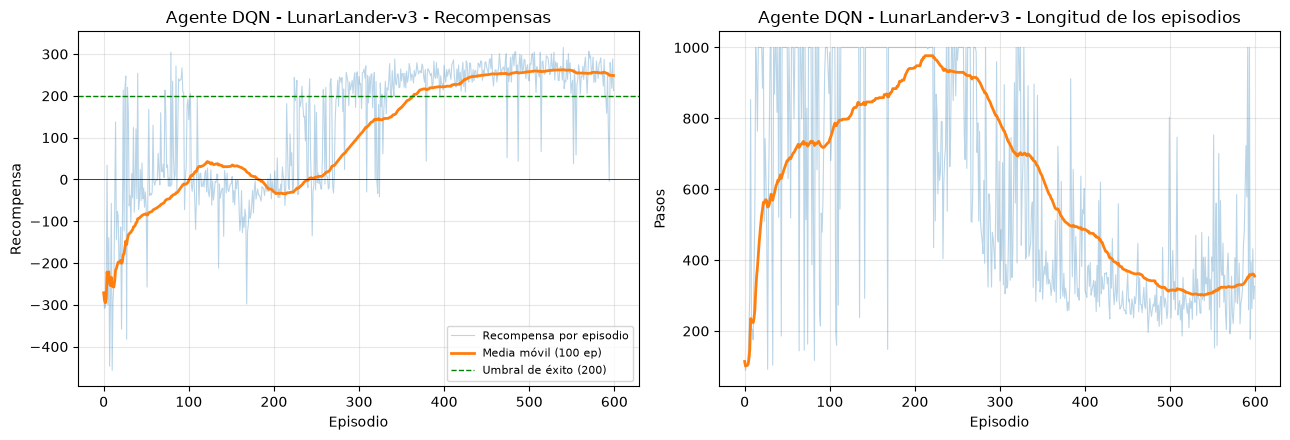

Resultados de los últimos 100 episodios de entrenamiento:
Recompensa promedio: 248.58
Tasa de éxito (R ≥ 200): 93.0%
Epsilon final: nan


In [41]:
# Graficar progreso del entrenamiento
graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                "Agente DQN - LunarLander-v3")

# Resultados del final del entrenamiento (todavía con exploración residual)
ultimos = np.array(recompensas_episodios[-100:])
print("Resultados de los últimos 100 episodios de entrenamiento:")
print(f"Recompensa promedio: {ultimos.mean():.2f}")
print(f"Tasa de éxito (R ≥ 200): {(ultimos >= UMBRAL_EXITO).mean():.1%}")
print(f"Epsilon final: {getattr(agente_dqn, 'epsilon', float('nan')):.3f}")

In [42]:
# Opcional: guardar los pesos de la red para no reentrenar en otra sesión, p. ej.
torch.save(agente_dqn.policy_net.state_dict(), 'dqn_lunarlander.pt')
agente_dqn.policy_net.load_state_dict(torch.load('dqn_lunarlander.pt')).


## 8. Evaluación del agente entrenado

Se evalúan 200 episodios, sin exploración, sobre semillas fijas
(`10000 … 10199`). El agente aleatorio se vuelve a evaluar en la misma celda con
esas mismas semillas, de modo que ambos agentes enfrenten los mismos escenarios
iniciales.

In [43]:
# Evaluar el agente DQN entrenado
env = gym.make('LunarLander-v3')

print("Evaluando agente DQN entrenado (200 episodios, sin exploración)...")
resultados_dqn = evaluar_agente(agente_dqn, env, num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_dqn, "Agente DQN entrenado")

print("\nImplementación de referencia para comparar:")
resultados_aleatorio_200 = evaluar_agente(AgenteAleatorio(env.action_space, semilla=SEMILLA), env,
                                          num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio_200, "Agente aleatorio")

env.close()

Evaluando agente DQN entrenado (200 episodios, sin exploración)...

Agente DQN entrenado - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 94.0%
Recompensa promedio: 254.63
Recompensa mediana:  263.38
Desviación estándar: 41.15
Total de éxitos: 188 / 200

Implementación de referencia para comparar:

Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -183.17
Recompensa mediana:  -149.80
Desviación estándar: 111.96
Total de éxitos: 0 / 200


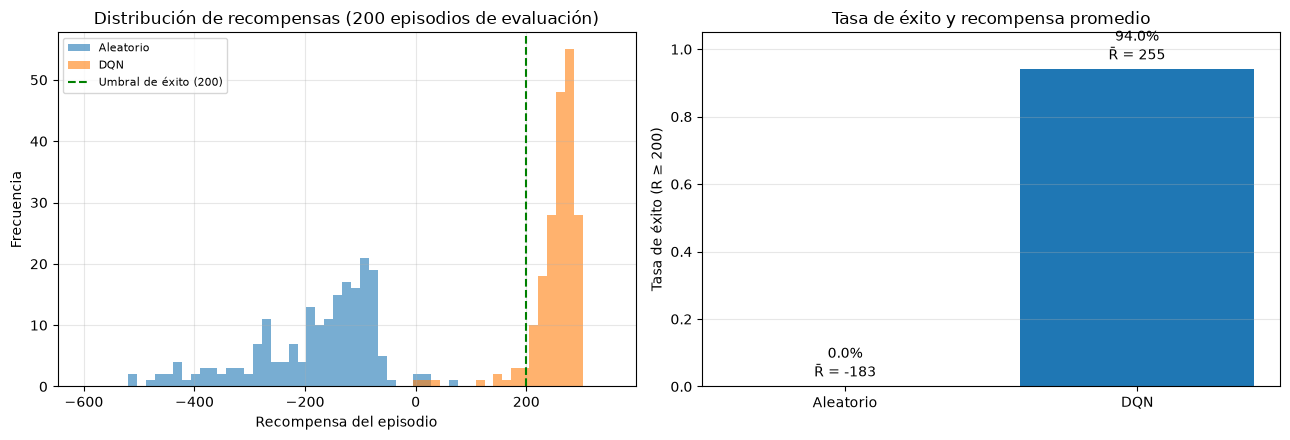

Tasa de éxito DQN:       94.0%
Tasa de éxito Aleatorio: 0.0%
Mejora en recompensa promedio: 437.8 puntos

Desglose de los 200 episodios del DQN:
  R ≥  200:  94.0%
  R ≥  150:  98.0%
  R ≥  100:  98.5%
  R ≥    0: 100.0%
  Episodios que se estrellan (R < -50): 0.0%


In [44]:
# Comparación gráfica: DQN vs. agente aleatorio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(-600, 350, 60)
ax1.hist(resultados_aleatorio_200['recompensas_totales'], bins=bins, alpha=0.6, label="Aleatorio")
ax1.hist(resultados_dqn['recompensas_totales'], bins=bins, alpha=0.6, label="DQN")
ax1.axvline(UMBRAL_EXITO, color='green', linestyle='--', label="Umbral de éxito (200)")
ax1.set_title("Distribución de recompensas (200 episodios de evaluación)")
ax1.set_xlabel("Recompensa del episodio")
ax1.set_ylabel("Frecuencia")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

nombres = ["Aleatorio", "DQN"]
tasas = [resultados_aleatorio_200['tasa_exito'], resultados_dqn['tasa_exito']]
promedios = [resultados_aleatorio_200['recompensa_promedio'], resultados_dqn['recompensa_promedio']]

barras = ax2.bar(nombres, tasas, color=['tab:gray', 'tab:blue'])
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Tasa de éxito (R ≥ 200)")
ax2.set_title("Tasa de éxito y recompensa promedio")
for barra, tasa, promedio in zip(barras, tasas, promedios):
    ax2.text(barra.get_x() + barra.get_width() / 2, tasa + 0.03,
             f"{tasa:.1%}\nR̄ = {promedio:.0f}", ha='center', fontsize=10)
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Tasa de éxito DQN:       {resultados_dqn['tasa_exito']:.1%}")
print(f"Tasa de éxito Aleatorio: {resultados_aleatorio_200['tasa_exito']:.1%}")
print(f"Mejora en recompensa promedio: "
      f"{resultados_dqn['recompensa_promedio'] - resultados_aleatorio_200['recompensa_promedio']:.1f} puntos")

# El umbral de 200 es un corte tajante: desglose de la cola de la distribución.
r_dqn = resultados_dqn['recompensas_totales']
print("\nDesglose de los 200 episodios del DQN:")
for corte in (200, 150, 100, 0):
    print(f"  R ≥ {corte:4d}: {(r_dqn >= corte).mean():6.1%}")
print(f"  Episodios que se estrellan (R < -50): {(r_dqn < -50).mean():.1%}")

## 9. Visualización de la política aprendida

Se corren 10 episodios sin exploración sobre semillas sorteadas, sin elegir
los que salieron bien, y se arma un GIF con los diez en una grilla. Cada cuadro
muestra al terminar la recompensa del episodio, en verde si llegó al umbral de éxito
y en rojo si no.

  semilla 20892:  241 pasos, recompensa   282.1
  semilla 27739:  312 pasos, recompensa   259.3
  semilla 26545:  273 pasos, recompensa   245.7
  semilla 24388:  265 pasos, recompensa   274.7
  semilla 24330:  333 pasos, recompensa   278.5
  semilla 28585:  327 pasos, recompensa   281.0
  semilla 20859:  347 pasos, recompensa   216.8
  semilla 26973:  257 pasos, recompensa   301.0
  semilla 22014:  360 pasos, recompensa   247.5
  semilla 20941:  262 pasos, recompensa   248.3

10/10 episodios exitosos, recompensa media 263.5 → aterrizaje_dqn.gif


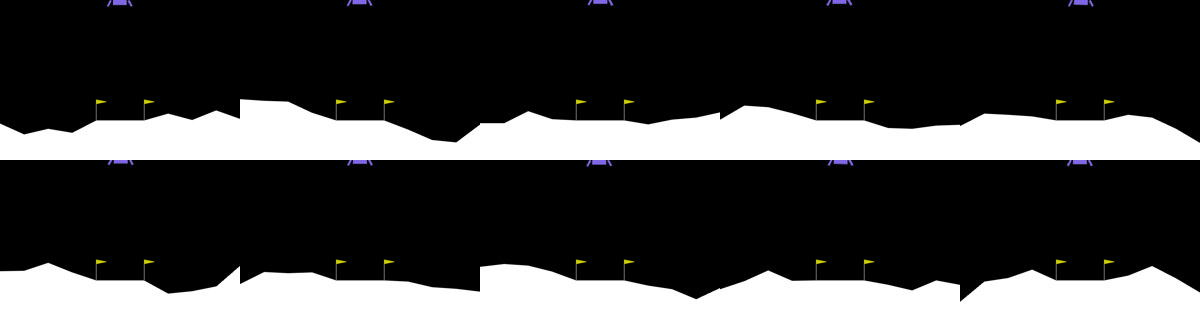

In [45]:
from PIL import Image, ImageDraw
from IPython.display import Image as MostrarImagen, display

ANCHO_CUADRO, ALTO_CUADRO = 240, 160

def _correr_episodio_render(agente, env, semilla, salto):
    """Corre un episodio renderizando y devuelve (cuadros, recompensa, pasos)."""
    estado, _ = env.reset(seed=semilla)
    cuadros, recompensa_total, paso = [], 0.0, 0
    while True:
        if paso % salto == 0:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
        estado, recompensa, terminado, truncado, _ = env.step(agente.elegir_accion(estado, explorar=False))
        recompensa_total += recompensa
        paso += 1
        if terminado or truncado:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
            break
    return cuadros, recompensa_total, paso


def _rotular(cuadro, recompensa, umbral):
    """Escribe la recompensa final sobre el cuadro: verde si es éxito, rojo si no."""
    cuadro = cuadro.copy()
    color = (40, 170, 70) if recompensa >= umbral else (210, 50, 50)
    ImageDraw.Draw(cuadro).text((6, 4), f"R = {recompensa:.0f}", fill=color)
    return cuadro


def grabar_episodios(agente, ruta_gif='aterrizaje_dqn.gif', semillas=range(10_000, 10_010),
                     columnas=5, salto=3, umbral=UMBRAL_EXITO):
    """Corre un episodio sin exploración por semilla y guarda un GIF con todos en
    una grilla. Los episodios que terminan antes quedan quietos en su último cuadro,
    rotulado con la recompensa obtenida."""
    env = gym.make('LunarLander-v3', render_mode='rgb_array')
    episodios = []
    try:
        for semilla in semillas:
            cuadros, recompensa_total, pasos = _correr_episodio_render(agente, env, semilla, salto)
            print(f"  semilla {semilla}: {pasos:4d} pasos, recompensa {recompensa_total:7.1f}")
            cuadros[-1] = _rotular(cuadros[-1], recompensa_total, umbral)
            episodios.append((cuadros, recompensa_total))
    finally:
        env.close()

    filas = -(-len(episodios) // columnas)
    largo = max(len(cuadros) for cuadros, _ in episodios)
    fotogramas = []
    for t in range(largo):
        lienzo = Image.new('RGB', (columnas * ANCHO_CUADRO, filas * ALTO_CUADRO), 'white')
        for i, (cuadros, _) in enumerate(episodios):
            lienzo.paste(cuadros[min(t, len(cuadros) - 1)],
                         ((i % columnas) * ANCHO_CUADRO, (i // columnas) * ALTO_CUADRO))
        fotogramas.append(lienzo)
    fotogramas[0].save(ruta_gif, save_all=True, append_images=fotogramas[1:], duration=50, loop=0)

    recompensas = np.array([r for _, r in episodios])
    print(f"\n{(recompensas >= umbral).sum()}/{len(recompensas)} episodios exitosos, "
          f"recompensa media {recompensas.mean():.1f} → {ruta_gif}")
    return ruta_gif, recompensas


# Semillas sorteadas, no elegidas: el GIF muestra los diez episodios salgan como salgan.
semillas_gif = np.random.default_rng(SEMILLA).integers(20_000, 30_000, size=10).tolist()
ruta, _ = grabar_episodios(agente_dqn, semillas=semillas_gif)
display(MostrarImagen(filename=ruta))

## 10. Qué aprendió la política

Analicen la política aprendida utilizando cortes con valores fijos en algunas
dimensiones para validar lo aprendido.


In [ ]:
# TODO 2: cortes de la política
raise NotImplementedError('TODO 2: cortes de la política')


## 11. Estudio de ablación

Las secciones anteriores muestran que el DQN completo funciona, pero no *cuánto*
aporta cada una de sus piezas. Una **ablación** responde eso: se reentrena el
agente desde cero desactivando (o degradando) un componente por vez y se mide
cuánto cae el desempeño respecto de la configuración completa.

Comparen el DQN completo contra, como mínimo, tres variantes correspondientes a
quitar características de DQN. Cada configuración se entrena con varias semillas y
se evalúa sobre las mismas semillas de evaluación, sin exploración. Reporten para
cada variante la recompensa de evaluación por semilla y comparen contra el DQN
completo con un test estadístico adecuado.


In [ ]:
# TODO 3: estudio de ablación
raise NotImplementedError('TODO 3: estudio de ablación')


# A. Elección de hiperparámetros

In [12]:
SEMILLA_EVAL = 10_000
EPISODIOS_POR_BLOQUE = 50
NUM_BLOQUES = 10          # 10 x 50 = 500 episodios
EPISODIOS_EVAL = 20
ULTIMAS_EVALS = 4         # promedio de las últimas 4 evaluaciones

def retorno_medio(resultados) -> float:
    return float(resultados["recompensa_promedio"])

def sugerir_hiperparametros(trial: optuna.Trial) -> dict:
    n_capas = trial.suggest_int("n_capas", 1, 3)
    neuronas = trial.suggest_categorical("neuronas", [64, 128, 256])
    return dict(
        lr=trial.suggest_float("lr", 1e-5, 3e-3, log=True),
        # buscamos 1-gamma en escala log: resuelve mejor la zona cercana a 1
        gamma=1.0 - trial.suggest_float("one_minus_gamma", 1e-3, 5e-2, log=True),
        batch_size=trial.suggest_categorical("batch_size", [64, 128, 256]),
        memory_size=trial.suggest_int("memory_size", 10_000, 200_000, log=True),
        eps_start=0.99,
        eps_end=trial.suggest_float("eps_end", 0.01, 0.1, log=True),
        eps_decay=trial.suggest_int("eps_decay", 500, 20_000, log=True),
        tau=trial.suggest_float("tau", 1e-3, 5e-2, log=True),
        hidden_layers=[neuronas] * n_capas,
    )

def objective(trial: optuna.Trial) -> float:
    hp = sugerir_hiperparametros(trial)
    env = gym.make("LunarLander-v3")
    try:
        agente = AgenteDQN(env.observation_space, env.action_space,
                           semilla=SEMILLA, **hp)
        evals = []
        for bloque in range(NUM_BLOQUES):
            # Variamos la semilla por bloque
            # para que el entorno no repita las mismas condiciones iniciales.
            entrenar_agente(
                agente, env,
                num_episodios=EPISODIOS_POR_BLOQUE,
                max_pasos=1000,
                umbral_resolucion=None,
                semilla=SEMILLA + bloque * EPISODIOS_POR_BLOQUE,
                verbose=False,
            )
            res = evaluar_agente(agente, env, num_episodios=EPISODIOS_EVAL,
                                 semilla=SEMILLA_EVAL)
            evals.append(retorno_medio(res))

            # Valor intermedio suavizado: promedio de las últimas evaluaciones
            valor = float(np.mean(evals[-ULTIMAS_EVALS:]))
            trial.report(valor, step=bloque)
            if trial.should_prune():
                raise optuna.TrialPruned()

        return float(np.mean(evals[-ULTIMAS_EVALS:]))
    finally:
        env.close()

In [61]:
study = optuna.create_study(
    study_name="dqn_lunarlander",
    storage="sqlite:///dqn_optuna.db",
    load_if_exists=True,
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=0, multivariate=True,
                                       n_startup_trials=10),
    # Poda: corta a los 30% peores, y no antes de la
    # evaluación 4 (episodio ~200), para no matar a los que empiezan peor.
    pruner=optuna.pruners.PercentilePruner(
        percentile=70.0, n_startup_trials=8, n_warmup_steps=3),
)
study.optimize(objective, n_trials=60)

completos = [t for t in study.trials
             if t.state == optuna.trial.TrialState.COMPLETE]
top5 = sorted(completos, key=lambda t: t.value, reverse=True)[:5]
print("\nMejores 5 configuraciones:")
for t in top5:
    print(f"  trial {t.number}: valor={t.value:.1f}  params={t.params}")

study.trials_dataframe().to_csv("dqn_optuna_trials.csv", index=False)

[I 2026-10-31 23:22:16,532] Using an existing study with `study_name='dqn_lunarlander'` instead of creating a new one.


Tiempo total de entrenamiento: 26s
Tiempo total de entrenamiento: 48s
Tiempo total de entrenamiento: 49s
Tiempo total de entrenamiento: 42s
Tiempo total de entrenamiento: 39s
Tiempo total de entrenamiento: 40s
Tiempo total de entrenamiento: 35s
Tiempo total de entrenamiento: 35s
Tiempo total de entrenamiento: 41s
Tiempo total de entrenamiento: 40s


[I 2026-10-31 23:29:01,614] Trial 4 finished with value: 146.32675009348506 and parameters: {'n_capas': 2, 'neuronas': 64, 'lr': 0.00011205837185064171, 'one_minus_gamma': 0.012512806369135352, 'batch_size': 256, 'memory_size': 31540, 'eps_end': 0.06190490166774184, 'eps_decay': 3516, 'tau': 0.0092276405837477}. Best is trial 4 with value: 146.32675009348506.


Tiempo total de entrenamiento: 50s
Tiempo total de entrenamiento: 64s
Tiempo total de entrenamiento: 64s
Tiempo total de entrenamiento: 68s
Tiempo total de entrenamiento: 1330s
Tiempo total de entrenamiento: 62s
Tiempo total de entrenamiento: 70s
Tiempo total de entrenamiento: 56s
Tiempo total de entrenamiento: 53s
Tiempo total de entrenamiento: 48s


[I 2026-11-01 00:00:20,709] Trial 5 finished with value: 112.98373193916687 and parameters: {'n_capas': 3, 'neuronas': 128, 'lr': 0.0011547828262799351, 'one_minus_gamma': 0.020992539475792136, 'batch_size': 128, 'memory_size': 39846, 'eps_end': 0.06032942364042932, 'eps_decay': 773, 'tau': 0.012223810830983162}. Best is trial 4 with value: 146.32675009348506.


Tiempo total de entrenamiento: 8s
Tiempo total de entrenamiento: 8s
Tiempo total de entrenamiento: 26s
Tiempo total de entrenamiento: 40s
Tiempo total de entrenamiento: 35s
Tiempo total de entrenamiento: 35s
Tiempo total de entrenamiento: 52s
Tiempo total de entrenamiento: 42s
Tiempo total de entrenamiento: 22s
Tiempo total de entrenamiento: 14s


... (112 outputs left out)

[I 2026-11-01 13:34:49,544] Trial 62 pruned. 


Tiempo total de entrenamiento: 36s
Tiempo total de entrenamiento: 38s
Tiempo total de entrenamiento: 32s
Tiempo total de entrenamiento: 27s
Tiempo total de entrenamiento: 26s
Tiempo total de entrenamiento: 20s
Tiempo total de entrenamiento: 25s
Tiempo total de entrenamiento: 19s
Tiempo total de entrenamiento: 17s
Tiempo total de entrenamiento: 16s


[I 2026-11-01 13:39:13,123] Trial 63 finished with value: 230.13824942880626 and parameters: {'n_capas': 3, 'neuronas': 128, 'lr': 0.00018403495617333186, 'one_minus_gamma': 0.00816306197283623, 'batch_size': 64, 'memory_size': 10918, 'eps_end': 0.03772526960683219, 'eps_decay': 1043, 'tau': 0.001119905919682069}. Best is trial 15 with value: 252.47484571154598.



Mejores 5 configuraciones:
  trial 15: valor=252.5  params={'n_capas': 3, 'neuronas': 128, 'lr': 0.000217808146262102, 'one_minus_gamma': 0.003508168602396034, 'batch_size': 64, 'memory_size': 16327, 'eps_end': 0.03542535131893156, 'eps_decay': 681, 'tau': 0.002470706175649911}
  trial 59: valor=250.5  params={'n_capas': 3, 'neuronas': 128, 'lr': 0.00013045711381021706, 'one_minus_gamma': 0.011008688304530462, 'batch_size': 64, 'memory_size': 12815, 'eps_end': 0.034331290114461524, 'eps_decay': 815, 'tau': 0.0018682428490525477}
  trial 26: valor=249.2  params={'n_capas': 3, 'neuronas': 128, 'lr': 0.0001535488372920553, 'one_minus_gamma': 0.0075826490941195, 'batch_size': 64, 'memory_size': 10763, 'eps_end': 0.028587046027247758, 'eps_decay': 1423, 'tau': 0.0022219759175441125}
  trial 42: valor=240.8  params={'n_capas': 3, 'neuronas': 128, 'lr': 0.00029105500383108445, 'one_minus_gamma': 0.011180772496368886, 'batch_size': 64, 'memory_size': 11405, 'eps_end': 0.03845047506502874, 'ep